In [1]:
from LombScargle_functions import *
from Louis_2026_PREX_NDA_usefulfunctions import *

In [2]:
# Restore the catalog data
obs, em, obsg, emg, obseph, emeph, n_obs, n_em, n_emg, nemg, nobs, num = restore_cat(1990, 2100, 0, 0, 0, 40)


In [3]:
(t_obsg, t, x, x_non_io, x_io, fmin, fmax) = organize_catalogue_for_Louis_PREX_2026(
                                                    obs, em,
                                                    obsg, emg,
                                                    obseph, emeph,
                                                    n_obs, n_em, n_emg, nemg, nobs, num)

In [4]:
SOURCE_NAME = {0:"undefined",
                1:"Io-A",
                2:"Io-A'",
                3:"Io-A''",
                4:"Io-B",
                5:"Io-B'",
                6:"Io-C",
                7:"Io-D",
                8:"non-Io-A",
                9:"non-Io-B",
                10:"non-Io-C",
                11:"non-Io-D"}


In [5]:
t_yyyyddd = doy_specific_year_to_yyyyddd((t/1440), 1990)
t_datetime = doy_to_datetime(t_yyyyddd)
print(t_datetime[0], t_datetime[-1])

#t_obsg_yyyyddd = doy_specific_year_to_yyyyddd((t_obsg/1440), 1990)
#t_obsg_datetime = doy_to_datetime(t_obsg_yyyyddd)
#print(t_obsg_datetime[0], t_obsg_datetime[-1])

1990-01-01 04:37:59 2020-04-14 17:28:59


In [6]:
time_timestamp = datetime_to_timestamp_old(numpy.array(t_datetime))

In [7]:
frequency = numpy.arange(8,45,1)

In [8]:
x_all_2D  = numpy.zeros([x.shape[0],frequency.shape[0]])
x_non_io_2D  = numpy.zeros([x_non_io.shape[0],frequency.shape[0]])
x_io_2D  = numpy.zeros([x_io.shape[0],frequency.shape[0]])


for ifreq, freq in enumerate(frequency[:-1]):
    mask_freq = (fmin >= freq) * (fmax <= frequency[ifreq+1])
    x_all_2D[mask_freq,ifreq] = x[mask_freq]
    x_non_io_2D[mask_freq,ifreq] = x_non_io[mask_freq]
    x_io_2D[mask_freq,ifreq] = x_io[mask_freq]


In [9]:
title = 'All Freq - All Data - All Stokes V/I'
y_zoomin_2D_periodogram = (8,43)
log_x_scale = False
cmap = 'Greys' 

add_extra_T_non_Io = {'Jupiter/2': {'T_value': 4.975, 'T_name': '$\\frac{J}{2}$'},
 'Jup_day_harm': {'T_value': 7.028, 'T_name': 'D-J$_{harm}$'},
 'Jupiter': {'T_value': 9.9249125, 'T_name': 'Jupiter'},
 'Day/2': {'T_value': 11.965, 'T_name': '$\\frac{day}{2}$'},
 'D-J_syn': {'T_value': 16.95, 'T_name': 'D-J$_{syn}$'},
 'Day': {'T_value': 23+56/60+4/60/60, 'T_name': 'day'},
 'Jupiter Transit': {'T_value': 23+55/60+48/60/60 , 'T_name': 'Jupiter\nTransit'},
 'Io/2':{'T_value': 21.229, 'T_name': f'Io/2'},
 'Io_syn': {'T_value': 12.96, 'T_name': r'Io$_{syn}$'},
  'Io':  {'T_value': 42.46, 'T_name': f'Io'},
 }


x_zoomin = [9.84, 10.32]
x_no_zoomin = [4,45]
y_zoomin = [0, 0.00005]
T_search = 12.992/24
T1 = 4
T2 = 45

data: 0.0, 0.0


/Users/clouis/anaconda3/envs/python3.8/lib/python3.8/site-packages/astropy/timeseries/periodograms/lombscargle/implementations/fast_impl.py:134: RuntimeWarning: invalid value encountered in divide
  power /= YY


data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 0.0
data: -1.0, 1.0
data: -1.0, 0.0
data: -1.0, 1.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
power_LS: 0.0, 3.7093975275752476e-05
8.151247608886152 53.60989366153697


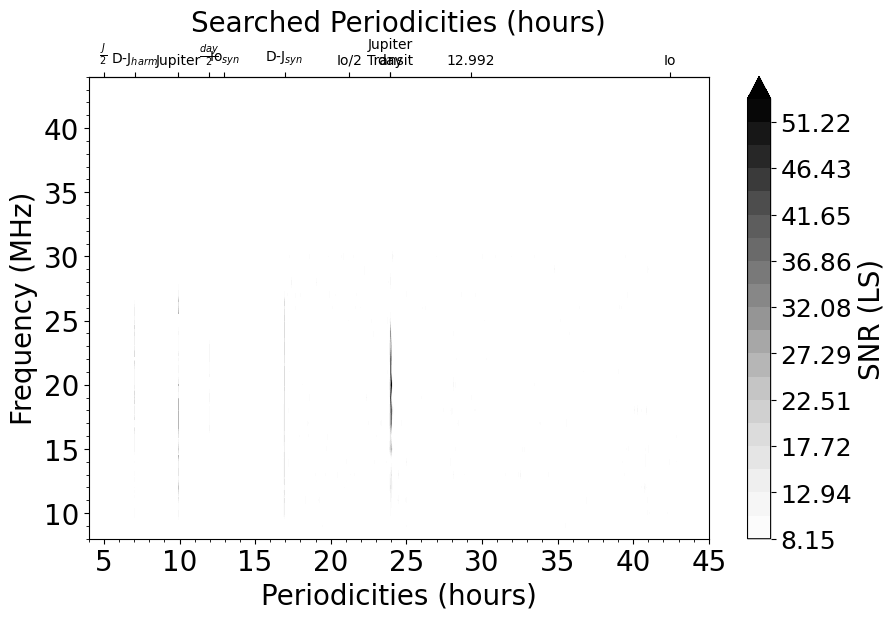

[9.92304934 9.9287068 ]
9.925878069537543


In [13]:

(frequency_LS_non_io, frequencies_non_io, power_LS_full_non_io) = calculate_LS_and_plot_2D_SNR(time_timestamp,frequency, x_non_io_2D,
                                                        T_search*24, title, log_x_scale=log_x_scale,
                                                        x_zoomin=x_no_zoomin, y_zoomin = y_zoomin,
                                                        #y_T_arrow = y_T_arrow
                                                        add_extra_T=add_extra_T_non_Io,
                                                        cmap = cmap,
                                                        vmin = "auto", vmax = None,
                                                        vmin_auto_percentile_value=99.97,
                                                        SNR_limit = 40, T1 = T1, T2 = T2, T_lin = False, nout = 10000000)


SNR_LS_2D = numpy.zeros(power_LS_full_non_io.shape)
for i_freq, freq in enumerate(frequencies_non_io):
    SNR_tmp =  numpy.nanstd(power_LS_full_non_io[i_freq,:]) 
    if SNR_tmp != 0:
        SNR_LS_2D[i_freq,:] = power_LS_full_non_io[i_freq,:]/SNR_tmp
        if numpy.median(SNR_LS_2D[i_freq,:]) >= 40:
            SNR_LS_2D[i_freq,:] = 0


from scipy.signal import find_peaks

# Step 1: Collapse power_LS along frequency_obs (rows)
collapsed_power = numpy.nanmean(SNR_LS_2D, axis=0)  


# Step 2: Find peaks
peaks, _ = find_peaks(collapsed_power, height = 10)  # adjust threshold as needed
peak_periods = 1 / frequency_LS_non_io[peaks] / 3600  # Convert to hours

print(numpy.sort(peak_periods[(peak_periods >= x_zoomin[0]) & (peak_periods <= x_zoomin[1])]))
print(numpy.mean(peak_periods[(peak_periods >= x_zoomin[0]) & (peak_periods <= x_zoomin[1])]))

5.235079939497031 40


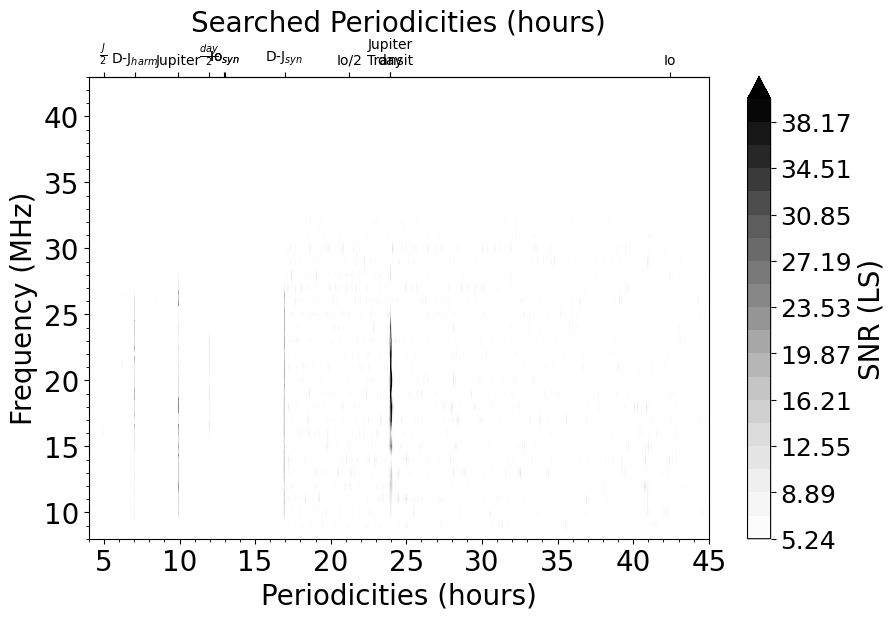

In [14]:
plot_SNR_LS_periodogram_2D(frequency_LS_non_io, frequencies_non_io, power_LS_full_non_io,
                        x_zoomin = x_no_zoomin,
                        y_zoomin = y_zoomin_2D_periodogram,
                        log_x_scale = log_x_scale,
                        #T_search = T_search, 
                        add_extra_T=add_extra_T_non_Io,
                        cmap = cmap,
                        vmin = "auto", vmax = 40,
                        vmin_auto_percentile_value=99.7,
                        SNR_limit = 40
                        )


In [15]:
x_zoomin_3 = [9.92424-0.24, 9.92424+0.24]

5.27 15


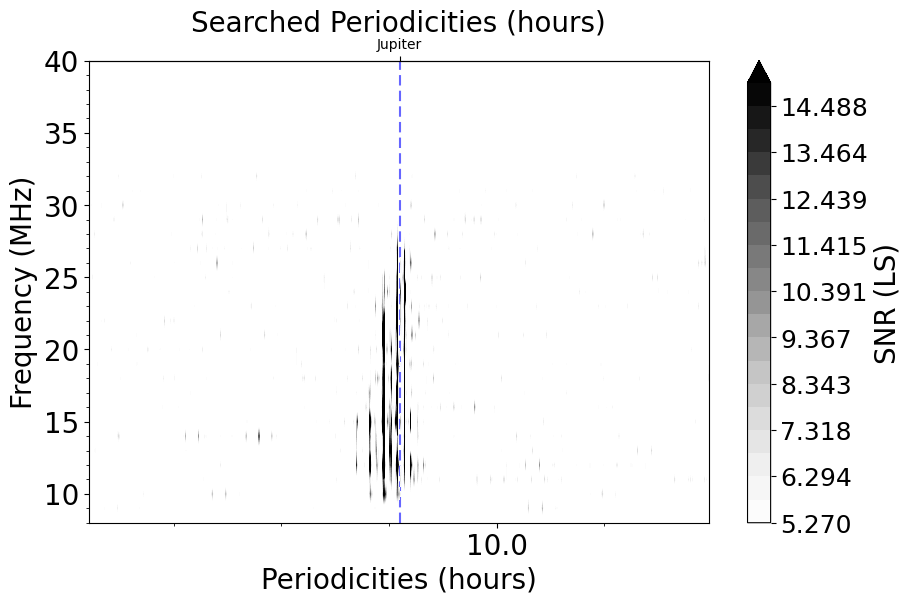

In [16]:
plot_SNR_LS_periodogram_2D(frequency_LS_non_io, frequencies_non_io, power_LS_full_non_io,
                        x_zoomin = x_zoomin_3,
                        y_zoomin = (8,40),
                        log_x_scale = log_x_scale,
                        #T_search = T_search, 
                        add_extra_T=add_extra_T_non_Io,
                        cmap = cmap,
                        vmin = 5.27, vmax = 15,
                        vmin_auto_percentile_value=95,
                        SNR_limit = 40,
                        vline = add_extra_T_non_Io['Jupiter']['T_value'],
                        color_vline='blue'
                        )


5.27 15


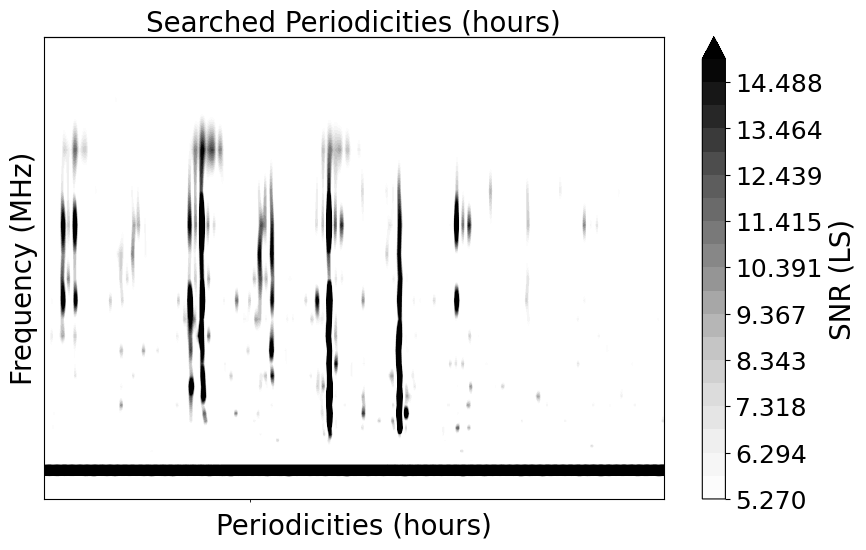

In [17]:
plot_SNR_LS_periodogram_2D(frequency_LS_non_io, 1/frequencies_non_io/60/60,power_LS_full_non_io[:, :],
                           x_zoomin=[9.9,9.95],vmin = 5.27, vmax = 15, cmap='Greys')



9.929998085330679
9.929995839331328
9.929993593332991
9.929991347335674
9.929989101339372
9.929986855344087
9.929984609349814
9.929982363356562
9.929980117364323
9.929977871373099
9.929975625382893
9.929973379393704
9.929971133405529
9.92996888741837
9.929966641432229
9.929964395447103
9.929962149462993
9.929959903479897
9.929957657497818
9.929955411516756
9.92995316553671
9.929950919557681
9.929948673579664
9.929946427602667
9.929944181626684
9.929941935651721
9.929939689677768
9.929937443704835
9.929935197732915
9.929932951762014
9.929930705792128
9.929928459823257
9.929926213855403
9.929923967888564
9.929921721922742
9.929919475957934
9.929917229994144
9.92991498403137
9.929912738069614
9.929910492108869
9.929908246149145
9.929906000190435
9.929903754232742
9.92990150827606
9.929899262320397
9.929897016365752
9.92989477041212
9.929892524459508
9.929890278507909
9.929888032557326
9.929885786607759
9.929883540659207
9.929881294711674
9.929879048765155
9.929876802819653
9.9298745568751

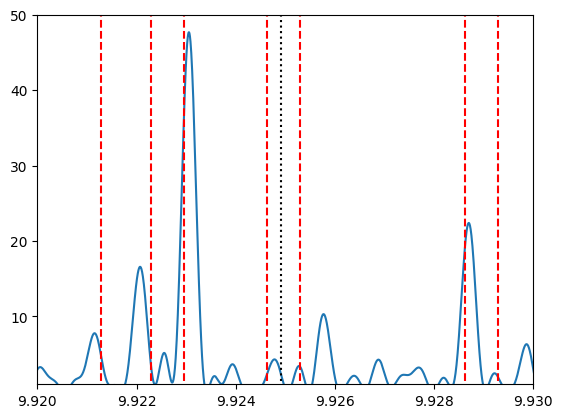

In [18]:
mask_f = frequencies_non_io==15
mask_T = ((1/frequency_LS_non_io/60/60) > 9.9) & ((1/frequency_LS_non_io/60/60) <9.95)
mask_T_2 = ((1/frequency_LS_non_io/60/60) > 9.92) & ((1/frequency_LS_non_io/60/60) <9.93)
plt.plot(1/frequency_LS_non_io[mask_T]/60/60, SNR_LS_2D[mask_f,mask_T])
plt.xlim(9.92,9.93)
plt.ylim(1,50)
for i_period in 1/frequency_LS_non_io[mask_T_2][SNR_LS_2D[mask_f,mask_T_2]>2]:
    print(i_period/60/60)
#plt.vlines(9.92295642, ymin= 0, ymax = 20, colors='red', linestyles='dashed')
#plt.vlines(9.9249125,  ymin= 0, ymax = 20, colors='red', linestyles='dashed')
#plt.vlines(9.92861943,  ymin= 0, ymax = 20, colors='red', linestyles='dashed')

plt.vlines(9.9249125,  ymin= 0, ymax = 50, colors='black', linestyles='dotted')

plt.vlines(9.92129206, ymin= 0, ymax = 50, colors='red', linestyles='dashed')
plt.vlines(9.92229061, ymin= 0, ymax = 50, colors='red', linestyles='dashed')
plt.vlines(9.92295642, ymin= 0, ymax = 50, colors='red', linestyles='dashed')
plt.vlines(9.92462134, ymin= 0, ymax = 50, colors='red', linestyles='dashed')
plt.vlines(9.92528747, ymin= 0, ymax = 50, colors='red', linestyles='dashed')
plt.vlines(9.92861943, ymin= 0, ymax = 50, colors='red', linestyles='dashed')
plt.vlines(9.92928609, ymin= 0, ymax = 50, colors='red', linestyles='dashed')



## IO

In [19]:


synodic_period_Moons = {
                 'Jupiter/2':{'T_value':4.975, 'T_name': r'$\frac{J}{2}$'},
                 'Jup_day_harm': {'T_value': 7.028, 'T_name': r'D-J$_{harm}$'},
                 'Jupiter': {'T_value': 9.93, 'T_name': 'Jupiter'},
                 'Ganymede_syn': {'T_value': 10.54, 'T_name': r'Gan$_{syn}$'},
                 'Europa_syn': {'T_value': 11.24, 'T_name': r'Eur$_{syn}$'},
                 'Day/2': {'T_value': 11.965, 'T_name': r'$\frac{day}{2}$'},
                 'Io_syn': {'T_value': 12.96, 'T_name': r'Io$_{syn}$'},
                 'D-J_syn': {'T_value': 16.95, 'T_name': r'D-J$_{syn}$'},
                 'Io/2':{'T_value': 21.229, 'T_name': f'Io/2'},
                 'Day': {'T_value': 23.93, 'T_name': f'day'},
                 'D-IJ_syn': {'T_value': 28.22, 'T_name': r'D-IJ$_{syn}$'},
                 'I/2-IJ_syn': {'T_value': 33.21, 'T_name': r'I/2-IJ$_{syn}$'},
                 'Io':  {'T_value': 42.46, 'T_name': f'Io'},
                 'Europa':  {'T_value': 85.228344, 'T_name': f'Eu'},
                 'Ganymede':  {'T_value': 171.70927104, 'T_name': f'Ga'},
}


add_extra_T_2 = {'Europa': {'T_value': 85.228344, 'T_name': 'Eu'},
 'Ganymede': {'T_value': 171.70927104, 'T_name': 'Ga'},
 'Io': {'T_value': 42.46, 'T_name': 'Io'},
 'I/2-IJ_syn': {'T_value': 33.21, 'T_name': 'I/2-IJ$_{syn}$'},
 'D-IJ_syn': {'T_value': 28.224165821247038, 'T_name': 'D-IJ$_{syn}$'},
 #'Jupiter_transit-IJ_syn': {'T_value': 28.230348672368546, 'T_name': 'Transit-IJ$_{syn}$'},
 'D-IJ_harm': {'T_value': 8.41, 'T_name': 'D-IJ$_{beat}$'},
 'Day': {'T_value': 23+56/60+4/60/60, 'T_name': 'day'},
 #'Jupiter Transit': {'T_value': 23+55/60+48/60/60 , 'T_name': 'Jupiter\nTransit'},
 'Io/2': {'T_value': 21.229, 'T_name': 'Io/2'},
 'Io_syn': {'T_value': 12.951451838887856, 'T_name': 'Io$_{syn}$'},
 'Day/2': {'T_value': 11.965, 'T_name': '$\\frac{day}{2}$'}}

In [20]:
x_zoomin_1 = [42.46-0.24, 42.46+0.24]
x_zoomin_2 = [12.96 -0.24, 12.96+0.24]
x_zoomin_3 = [9.92424-0.24, 9.92424+0.24]
y_zoomin = [0, 0.00005]

data: 0.0, 0.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 1.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: -1.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
data: 0.0, 0.0
power_LS: 0.0, 6.32036247899097e-05
0 50


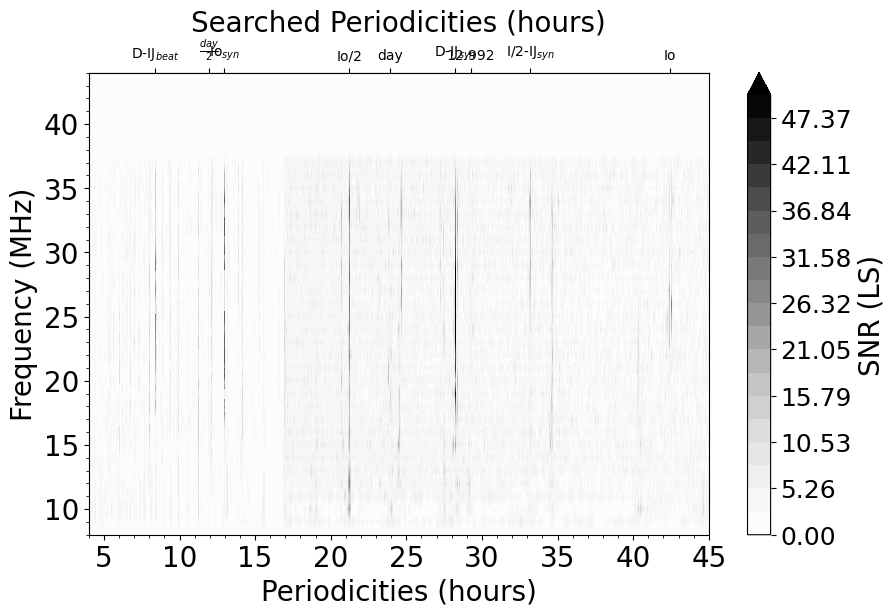

[42.52819312]
42.5281931233795


In [ ]:
(frequency_LS_io_all, frequencies_io_all, power_LS_full_io_all) = calculate_LS_and_plot_2D_SNR(time_timestamp,frequency, x_io_2D,
                                                        T_search*24, title, log_x_scale=log_x_scale,
                                                        x_zoomin=x_no_zoomin, y_zoomin = y_zoomin,
                                                        #y_T_arrow = y_T_arrow
                                                        add_extra_T=add_extra_T_2,
                                                        cmap = cmap,
                                                        vmin = 0, vmax = 50,
                                                        SNR_limit = 40,
                                                        T1 = T1, T2 = T2, T_lin = False, nout = 10000000)


SNR_LS_2D = numpy.zeros(power_LS_full_io_all.shape)
for i_freq, freq in enumerate(frequencies_io_all):
    SNR_tmp =  numpy.nanstd(power_LS_full_io_all[i_freq,:]) 
    if SNR_tmp != 0:
        SNR_LS_2D[i_freq,:] = power_LS_full_io_all[i_freq,:]/SNR_tmp
        if numpy.median(SNR_LS_2D[i_freq,:]) >= 40:
            SNR_LS_2D[i_freq,:] = 0




from scipy.signal import find_peaks

# Step 1: Collapse power_LS along frequency_obs (rows)
collapsed_power = numpy.nanmean(SNR_LS_2D, axis=0)  


# Step 2: Find peaks
peaks, _ = find_peaks(collapsed_power, height = 5)  # adjust threshold as needed
peak_periods = 1 / frequency_LS_io_all[peaks] / 3600  # Convert to hours

print(numpy.sort(peak_periods[(peak_periods >= x_zoomin_1[0]) & (peak_periods <= x_zoomin_1[1])]))
print(numpy.nanmean(peak_periods[(peak_periods >= x_zoomin_1[0]) & (peak_periods <= x_zoomin_1[1])]))


0.0 93.71677552609951


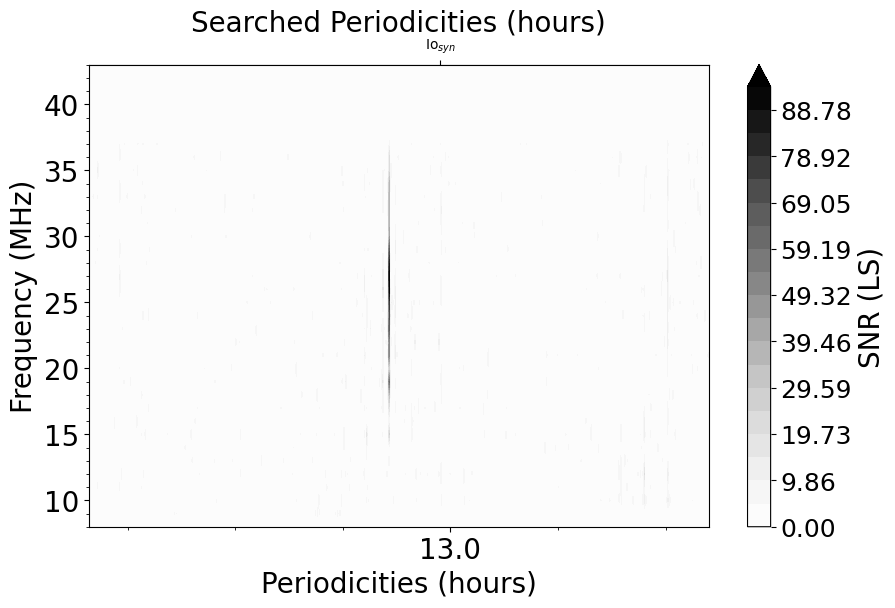

[12.95260467 13.16816921]
13.060386943402147
0.0 93.71677552609951


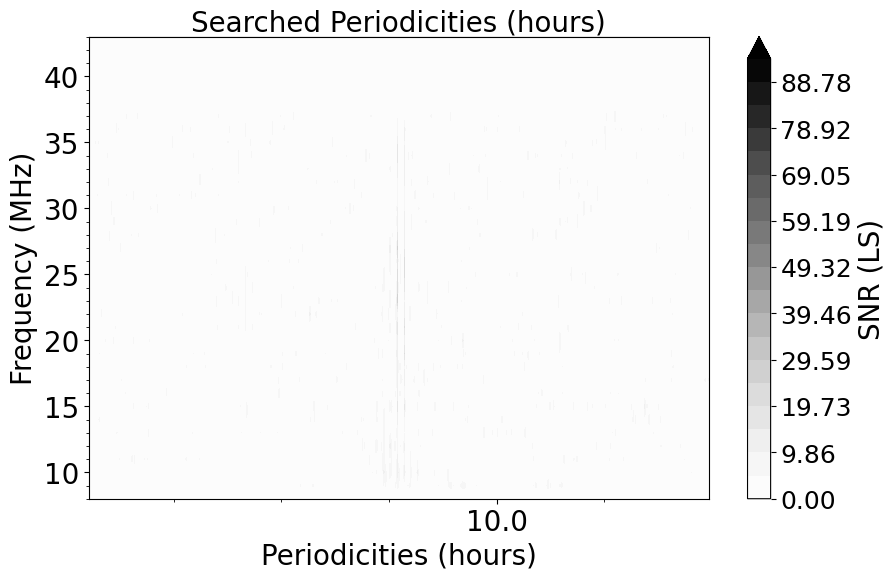

[9.92306279 9.92867088]
9.925866834858287


In [22]:

plot_SNR_LS_periodogram_2D(frequency_LS_io_all, frequencies_io_all, power_LS_full_io_all,
                        x_zoomin = x_zoomin_2,
                        y_zoomin = y_zoomin_2D_periodogram,
                        log_x_scale = log_x_scale,
                        T_search = T_search, 
                        vmin = None, vmax = None, cmap = cmap,
                        SNR_limit = 40)


print(numpy.sort(peak_periods[(peak_periods >= x_zoomin_2[0]) & (peak_periods <= x_zoomin_2[1])]))
print(numpy.nanmean(peak_periods[(peak_periods >= x_zoomin_2[0]) & (peak_periods <= x_zoomin_2[1])]))


plot_SNR_LS_periodogram_2D(frequency_LS_io_all, frequencies_io_all, power_LS_full_io_all,
                        x_zoomin = x_zoomin_3,
                        y_zoomin = y_zoomin_2D_periodogram,
                        log_x_scale = log_x_scale,
                        T_search = T_search, 
                        vmin = None, vmax = None, cmap = cmap,
                        SNR_limit = 40)


print(numpy.sort(peak_periods[(peak_periods >= x_zoomin_3[0]) & (peak_periods <= x_zoomin_3[1])]))
print(numpy.nanmean(peak_periods[(peak_periods >= x_zoomin_3[0]) & (peak_periods <= x_zoomin_3[1])]))


5.448413884873354 93.71677552609951


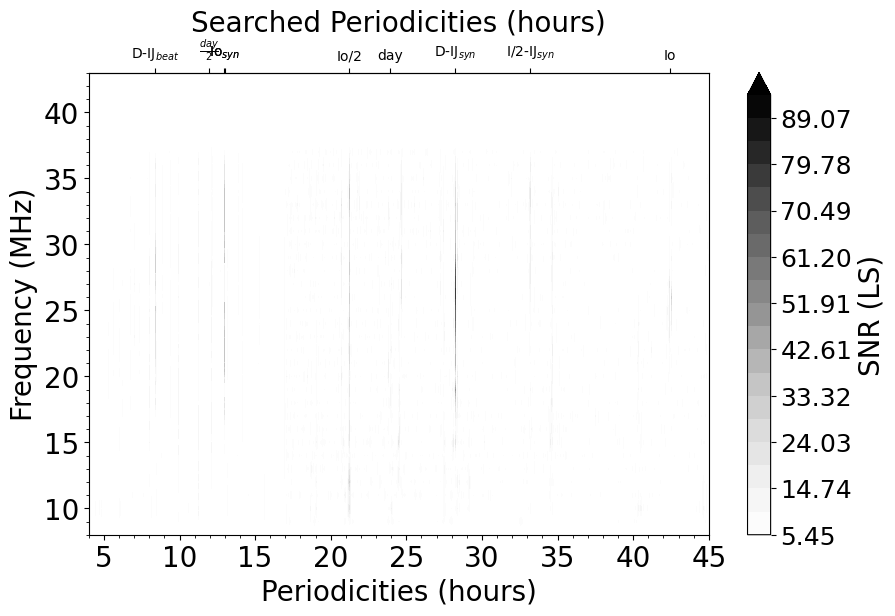

In [23]:
plot_SNR_LS_periodogram_2D(frequency_LS_io_all, frequencies_io_all, power_LS_full_io_all,
                        x_zoomin = x_no_zoomin,
                        y_zoomin = y_zoomin_2D_periodogram,
                        log_x_scale = log_x_scale,
                        #T_search = T_search, 
                        add_extra_T=add_extra_T_2,
                        cmap = cmap,
                        vmin = "auto",
                        vmax = None,
                        vmin_auto_percentile_value=99.7,
                        SNR_limit = 40)


5.49 15


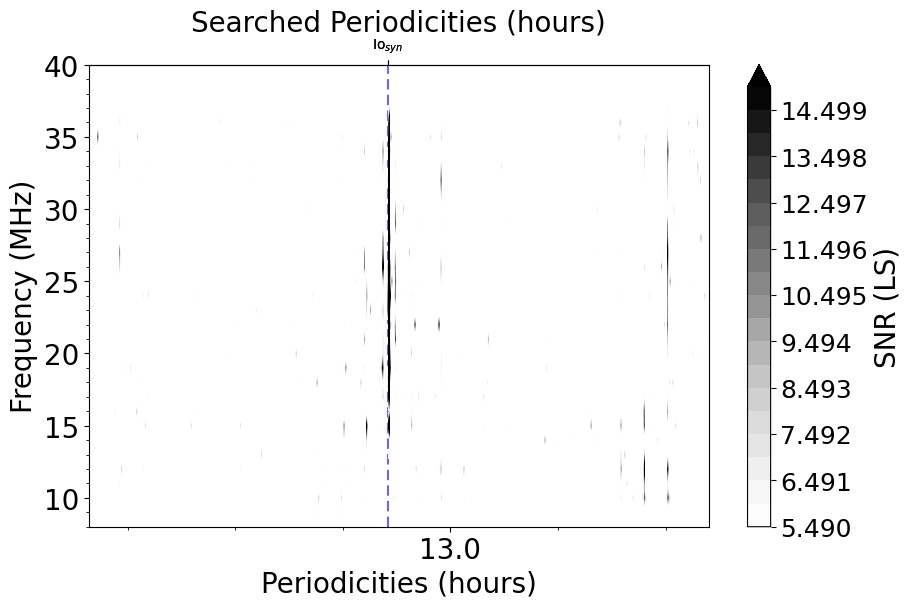

In [24]:
plot_SNR_LS_periodogram_2D(frequency_LS_io_all, frequencies_io_all, power_LS_full_io_all,
                        x_zoomin = x_zoomin_2,
                        y_zoomin = (8,40),
                        log_x_scale = log_x_scale,
                        T_search =  12.951451838887856/24, T_name = r'Io$_{syn}$',
                        cmap = cmap,
                        add_extra_T=add_extra_T_2,
                        vmin = 5.49, vmax = 15,
                        vmin_auto_percentile_value=95,
                        SNR_limit = 40,
                        vline =  12.951451838887856,
                        color_vline='blue'
                        )



5.49 15


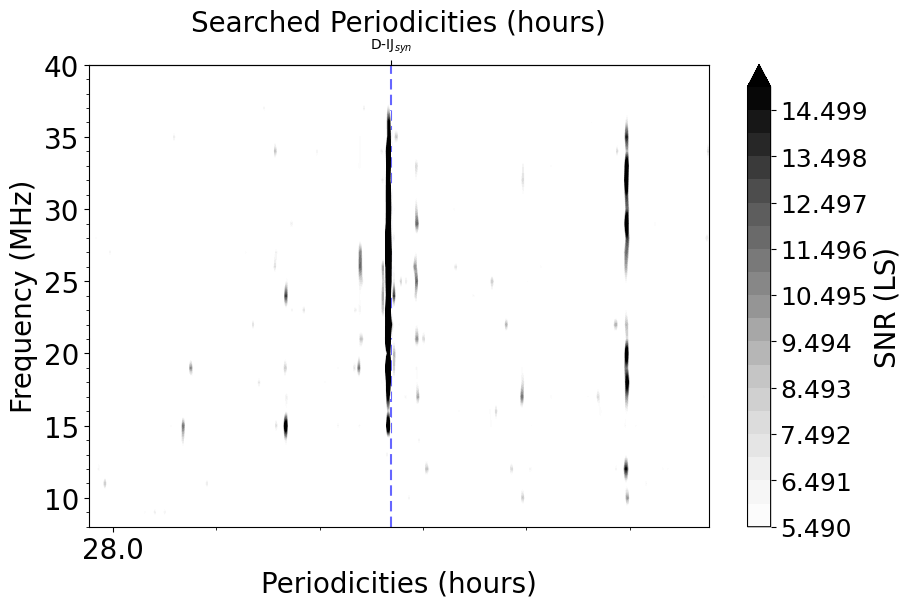

In [25]:
plot_SNR_LS_periodogram_2D(frequency_LS_io_all, frequencies_io_all, power_LS_full_io_all,
                        x_zoomin = (28.230348672368546-0.25, 28.230348672368546+0.25),
                        y_zoomin = (8,40),
                        log_x_scale = log_x_scale,
                        #T_search =  28.224165821247038/24, T_name = r'D-IJ$_{syn}$',
                        cmap = cmap,
                        add_extra_T=add_extra_T_2,
                        vmin = 5.49, vmax = 15,
                        vmin_auto_percentile_value=95,
                        SNR_limit = 40,
                        vline = True,
                        color_vline='blue'
                        )



### Save LS

In [28]:
numpy.save("frequency_LS_non_io_from_NDA", frequency_LS_non_io)
numpy.save("frequencies_non_io_from_NDA", frequencies_non_io)
numpy.save("power_LS_full_non_io_from_NDA", power_LS_full_non_io)

numpy.save("frequency_LS_io_from_NDA", frequency_LS_io_all)
numpy.save("frequencies_io_from_NDA", frequencies_io_all)
numpy.save("power_LS_full_io_from_NDA", power_LS_full_io_all)

In [ ]:
x_zoomin_1 = [42.46-0.24, 42.46+0.24]
x_zoomin_2 = [12.96 -0.24, 12.96+0.24]
x_zoomin_3 = [9.92424-0.24, 9.92424+0.24]
x_zoomin_4 = [10.53301411800384-0.24, 10.53301411800384+0.24]
x_zoomin_5 = [11.232144009821296-0.24, 11.232144009821296+0.24]

: 

# SNR OVER TIME IO

In [ ]:
x_tmp_io  = numpy.zeros([x_io.shape[0],1])
x_tmp_io[:,0] = x_io


for i_window_size in [60*24*500]:
        #for i_step_size in [24*60, 24*60*2, 24*60*4, 24*60*7, 24*60*15]:
        for i_step_size in [24*60*2]:
                filename = f'./outputs/LS_periodogram_over_time_window{int(i_window_size/60/24)}day_step{int(i_step_size/60/24)}day_NDA_catalog_only_Io.png'
                #if i_step_size <= i_window_size:
                (SNR_over_time_times_results_io, SNR_over_time_frequency_LS_io, SNR_over_time_power_results_io, SNR_over_time_SNR_LS_results_io) = calculate_and_plot_SNR_LS_periodogram_over_time(numpy.array(t_datetime), numpy.array([1]), x_tmp_io,
                                            cmap = 'Greys',
                                            exoplanet_period_in_hours = 12.993,
                                            hline_label = '',
                                            x_zoomin = None, # datetime object
                                            LS_y_zoomin = (x_zoomin_2[0], x_zoomin_2[1]),
                                            observed_frequency_limits = [1,1],
                                            LS_window_size = i_window_size,  # Number of points in each window (in minutes)
                                            LS_step_size = i_step_size,
                                            vmin = 5, vmax = 15,
                                            #add_extra_T = {'Io': {'T_value': 12.96, 'T_name': 'syn IJ'}},
                                            savefig = False, filename = filename,
                                            figsize = (40, 5*2),
                                            T1 = T1, T2 = T2, T_lin = False, nout = 1000000)



Frequency: 1 MHZ
1990-01-01 04:37:59, 1991-05-16 04:37:59
1990-01-03 04:37:59, 1991-05-18 04:37:59
1990-01-05 04:37:59, 1991-05-20 04:37:59
1990-01-07 04:37:59, 1991-05-22 04:37:59
1990-01-09 04:37:59, 1991-05-24 04:37:59
1990-01-11 04:37:59, 1991-05-26 04:37:59
1990-01-13 04:37:59, 1991-05-28 04:37:59
1990-01-15 04:37:59, 1991-05-30 04:37:59
1990-01-17 04:37:59, 1991-06-01 04:37:59
1990-01-19 04:37:59, 1991-06-03 04:37:59
1990-01-21 04:37:59, 1991-06-05 04:37:59
1990-01-23 04:37:59, 1991-06-07 04:37:59
1990-01-25 04:37:59, 1991-06-09 04:37:59
1990-01-27 04:37:59, 1991-06-11 04:37:59
1990-01-29 04:37:59, 1991-06-13 04:37:59
1990-01-31 04:37:59, 1991-06-15 04:37:59
1990-02-02 04:37:59, 1991-06-17 04:37:59
1990-02-04 04:37:59, 1991-06-19 04:37:59
1990-02-06 04:37:59, 1991-06-21 04:37:59
1990-02-08 04:37:59, 1991-06-23 04:37:59
1990-02-10 04:37:59, 1991-06-25 04:37:59
1990-02-12 04:37:59, 1991-06-27 04:37:59
1990-02-14 04:37:59, 1991-06-29 04:37:59
1990-02-16 04:37:59, 1991-07-01 04:37:59

In [ ]:
numpy.save("SNR_over_time_times_results_io_from_NDA", SNR_over_time_times_results_io)
numpy.save("SNR_over_time_frequency_LS_io_from_NDA", SNR_over_time_frequency_LS_io)
numpy.save("SNR_over_time_SNR_LS_results_io_from_NDA", SNR_over_time_SNR_LS_results_io)

In [ ]:
plot_SNR_LS_over_time(SNR_over_time_times_results_io,
                          SNR_over_time_frequency_LS_io,
                          SNR_over_time_SNR_LS_results_io,
                          numpy.array([1]),
                          observed_frequency_limits = [1,1],
                          extra_panel_data = None,
                          figsize = (40, 5*2),
                          vmin = 5.49, vmax = 15,
                          #vmin_auto_percentile_value = 99.7,
                          x_zoomin = None, # datetime object
                          LS_y_zoomin = (x_zoomin_2[0], x_zoomin_2[1]),
                          extra_panel_ytitle = None,
                          cmap = 'Greys',
                          hlines = [12.951451838887856])
                          #vlines_regular = 398.8613
                          

In [ ]:
plot_SNR_LS_over_time(SNR_over_time_times_results_io,
                          SNR_over_time_frequency_LS_io,
                          SNR_over_time_SNR_LS_results_io,
                          numpy.array([1]),
                          observed_frequency_limits = [1,1],
                          extra_panel_data = None,
                          figsize = (40, 5*2),
                          vmin = 5.49, vmax = 15,
                          #vmin_auto_percentile_value = 99.99,
                          x_zoomin = None, # datetime object
                          LS_y_zoomin = (28.230348672368546-0.25, 28.230348672368546+0.25),
                          extra_panel_ytitle = None,
                          cmap = 'Greys',
                          hlines = [28.224165821247038]
                          )

In [ ]:
numpy.save("SNR_over_time_times_results_io_from_NDA", SNR_over_time_times_results_io)
numpy.save("SNR_over_time_frequency_LS_io_from_NDA", SNR_over_time_frequency_LS_io)
numpy.save("SNR_over_time_SNR_LS_results_io_from_NDA", SNR_over_time_SNR_LS_results_io)

# SNR OVER TIME NON IO

In [ ]:
x_tmp_non_io  = numpy.zeros([x_non_io.shape[0],1])
x_tmp_non_io[:,0] = x_non_io


for i_window_size in [60*24*500]:
        #for i_step_size in [24*60, 24*60*2, 24*60*4, 24*60*7, 24*60*15]:
        for i_step_size in [24*60*2]:
                filename = f'./outputs/LS_periodogram_over_time_window{int(i_window_size/60/24)}day_step{int(i_step_size/60/24)}day_NDA_catalog_only_Io.png'
                #if i_step_size <= i_window_size:
                (SNR_over_time_times_results_non_io, SNR_over_time_frequency_LS_non_io, SNR_over_time_power_results_non_io, SNR_over_time_SNR_LS_results_non_io) = calculate_and_plot_SNR_LS_periodogram_over_time(numpy.array(t_datetime), numpy.array([1]), x_tmp_non_io,
                                            cmap = 'Greys',
                                            exoplanet_period_in_hours = 12.993,
                                            hline_label = '',
                                            x_zoomin = None, # datetime object
                                            LS_y_zoomin = (x_zoomin_3[0], x_zoomin_3[1]),
                                            observed_frequency_limits = [1,1],
                                            LS_window_size = i_window_size,  # Number of points in each window (in minutes)
                                            LS_step_size = i_step_size,
                                            vmin = 5, vmax = 15,
                                            #add_extra_T = {'Io': {'T_value': 12.96, 'T_name': 'syn IJ'}},
                                            savefig = False, filename = filename,
                                            figsize = (40, 5*2),
                                            T1 = T1, T2 = T2, T_lin = False, nout = 1000000)
                


Frequency: 1 MHZ
1990-01-01 04:37:59, 1991-05-16 04:37:59
1990-01-03 04:37:59, 1991-05-18 04:37:59
1990-01-05 04:37:59, 1991-05-20 04:37:59
1990-01-07 04:37:59, 1991-05-22 04:37:59
1990-01-09 04:37:59, 1991-05-24 04:37:59
1990-01-11 04:37:59, 1991-05-26 04:37:59
1990-01-13 04:37:59, 1991-05-28 04:37:59
1990-01-15 04:37:59, 1991-05-30 04:37:59
1990-01-17 04:37:59, 1991-06-01 04:37:59
1990-01-19 04:37:59, 1991-06-03 04:37:59
1990-01-21 04:37:59, 1991-06-05 04:37:59
1990-01-23 04:37:59, 1991-06-07 04:37:59
1990-01-25 04:37:59, 1991-06-09 04:37:59
1990-01-27 04:37:59, 1991-06-11 04:37:59
1990-01-29 04:37:59, 1991-06-13 04:37:59
1990-01-31 04:37:59, 1991-06-15 04:37:59
1990-02-02 04:37:59, 1991-06-17 04:37:59
1990-02-04 04:37:59, 1991-06-19 04:37:59
1990-02-06 04:37:59, 1991-06-21 04:37:59
1990-02-08 04:37:59, 1991-06-23 04:37:59
1990-02-10 04:37:59, 1991-06-25 04:37:59
1990-02-12 04:37:59, 1991-06-27 04:37:59
1990-02-14 04:37:59, 1991-06-29 04:37:59
1990-02-16 04:37:59, 1991-07-01 04:37:59

: 

In [ ]:
numpy.save("SNR_over_time_times_results_non_io", SNR_over_time_times_results_non_io)

numpy.save("SNR_over_time_frequency_LS_non_io", SNR_over_time_frequency_LS_non_io)
           
#numpy.save("SNR_over_time_power_results_non_io", SNR_over_time_power_results_non_io)
                     
numpy.save("SNR_over_time_SNR_LS_results_non_io", SNR_over_time_SNR_LS_results_non_io)

In [ ]:
plot_SNR_LS_over_time(SNR_over_time_times_results_non_io,
                          SNR_over_time_frequency_LS_non_io,
                          SNR_over_time_SNR_LS_results_non_io,
                          numpy.array([1]),
                          observed_frequency_limits = [1,1],
                          extra_panel_data = None,
                          figsize = (40, 5*2),
                          vmin = 5.27, vmax = 15,
                          x_zoomin = None, # datetime object
                          LS_y_zoomin = (x_zoomin_3[0], x_zoomin_3[1]),
                          extra_panel_ytitle = None,
                          cmap = 'Greys',
                          #hlines = [9.92425]
                          hlines = [9.9249125],
                          T1 = T1, T2 = T2, T_lin = False, nout = 1000000
                          )